In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# structure du dataset

In [2]:
df = pd.read_csv('../dataset/raw/hotel_bookings.csv')
df.shape

(119390, 32)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


# Valeurs manquantes (en nombre et en %)

In [5]:
manquants = df.isna().sum()
pct = (manquants / len(df) * 100).round(2)
pd.DataFrame({'nb_manquants': manquants, 'pct': pct})[manquants > 0].sort_values('pct', ascending=False)

,nb_manquants,pct
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


**Valeurs manquantes :** `company` est vide à 94 % → l'absence signifie « pas d'entreprise , on remplace par 0.
`agent` (14 %) → absence = « pas d'agent », remplacé par 0. `country` (488 lignes, 0,4 %) → remplacé par « Unknown ».


# Valeurs aberrantes

In [6]:
print("adr négatif :", (df['adr'] < 0).sum())
print("adr > 1000 :", (df['adr'] > 1000).sum())
print("0 nuit :", ((df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0).sum())
print("0 personne :", ((df['adults'] + df['children'].fillna(0) + df['babies']) == 0).sum())
print(df['meal'].value_counts())

adr négatif : 1
adr > 1000 : 1
0 nuit : 715
0 personne : 180
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64


**Valeurs aberrantes :**
- 2 prix incohérents (un négatif, un au-dessus de 1 000 €) : supprimés.
- 180 réservations sans aucun client : supprimées.
- 715 séjours de 0 nuit : gardés, ce sont peut-être des locations à la journée.
- Repas « Undefined » : regroupé avec « SC » (sans repas), qui veut dire la même chose.

# Cible et répartition des hôtels

In [7]:
print(df['is_canceled'].value_counts(normalize=True).round(3))
print(df['hotel'].value_counts())

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


In [8]:
df.duplicated().sum()

np.int64(31994)

# nettoyage

In [9]:
df_clean = df.copy()

# Valeurs manquantes
df_clean['children'] = df_clean['children'].fillna(0).astype(int)
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['agent'] = df_clean['agent'].fillna(0).astype(int)
df_clean['company'] = df_clean['company'].fillna(0).astype(int)

# Incohérences
df_clean = df_clean[(df_clean['adults'] + df_clean['children'] + df_clean['babies']) > 0]
df_clean = df_clean[(df_clean['adr'] >= 0) & (df_clean['adr'] < 1000)]
df_clean['meal'] = df_clean['meal'].replace('Undefined', 'SC')

# Format date
df_clean['reservation_status_date'] = pd.to_datetime(df_clean['reservation_status_date'])

print(df.shape, "→", df_clean.shape)
print("Manquants restants :", df_clean.isna().sum().sum())

(119390, 32) → (119208, 32)
Manquants restants : 0


**Bilan du nettoyage :** on passe de 119 390 à 119 208 réservations (182 lignes supprimées, soit 0,15 %). Il ne reste plus aucune valeur manquante. Les colonnes connues seulement après la réservation (`reservation_status`, `assigned_room_type`…) sont gardées pour l'analyse et le SQL ; elles seront retirées seulement pour le modèle.

# describe() pour repérer d’autres valeurs extrêmes  important

In [10]:
pd.crosstab(df_clean['reservation_status'], df_clean['is_canceled'])


is_canceled,0,1
reservation_status,,
Canceled,0,42992
Check-Out,75010,0
No-Show,0,1206


# Pourquoi 1 000 € comme seuil ?

In [11]:
print(df['adr'].sort_values(ascending=False).head(8).values)
print(df['adr'].quantile([0.5, 0.9, 0.99, 0.999]).round(1))

[5400.    510.    508.    451.5   450.    437.    426.25  402.  ]
0.500     94.6
0.900    164.0
0.990    252.0
0.999    326.2
Name: adr, dtype: float64


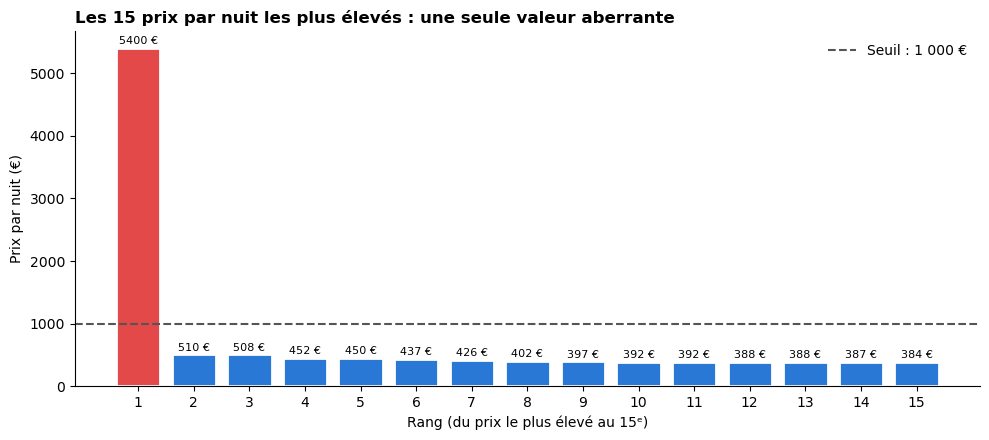

In [12]:
top = df['adr'].sort_values(ascending=False).head(15).reset_index(drop=True)
couleurs = ['#e34948' if v > 1000 else '#2a78d6' for v in top]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, 16), top, color=couleurs, edgecolor='white', linewidth=2)
ax.axhline(1000, color='#555555', linestyle='--', linewidth=1.5, label='Seuil : 1 000 €')
for i, v in enumerate(top, start=1):
    ax.text(i, v + 60, f'{v:.0f} €', ha='center', fontsize=8)
ax.set_title('Les 15 prix par nuit les plus élevés : une seule valeur aberrante',
             loc='left', fontweight='bold')
ax.set_xlabel('Rang (du prix le plus élevé au 15ᵉ)')
ax.set_ylabel('Prix par nuit (€)')
ax.set_xticks(range(1, 16))
ax.legend(frameon=False); sns.despine()
plt.tight_layout(); plt.savefig('fig_seuil_prix.png', dpi=150); plt.show()

 Le graphique montre qu'une seule valeur (5 400 €) se détache complètement. Le prix suivant n'est que de 510 €, soit 10 fois moins, et 99 % des prix sont inférieurs à 252 €. Le seuil de 1 000 € isole donc uniquement cette erreur, sans toucher aux prix élevés mais réalistes.
La méthode IQR (règle des « moustaches ») aurait classé environ 3 800 réservations comme aberrantes. Ce sont surtout de vraies grandes chambres en haute saison : nous ne l'avons donc pas appliquée.

#  Prix par type de chambre et par hôtel

In [13]:
prix_chambre = (df_clean.groupby(['hotel', 'reserved_room_type'])['adr']
                .agg(nb='size', prix_median='median', prix_max='max').round(0))
prix_chambre

nb  prix_median  prix_max
hotel        reserved_room_type                              
City Hotel   A                   62483         94.0     510.0
             B                    1112         87.0     284.0
             C                      13         90.0     212.0
             D                   11747        132.0     376.0
             E                    1537        162.0     452.0
             F                    1788        189.0     350.0
             G                     482        222.0     372.0
Resort Hotel A                   23388         61.0     508.0
             B                       3        110.0     134.0
             C                     918        163.0     367.0
             D                    7432         83.0     351.0
             E                    4982         98.0     382.0
             F                    1106        118.0     392.0
             G                    1610        155.0     426.0
             H                     601        184.0     437.0
             L                       6        143.0     200.0

In [14]:
COULEURS = {'City Hotel': '#2a78d6', 'Resort Hotel': '#eb6834'}

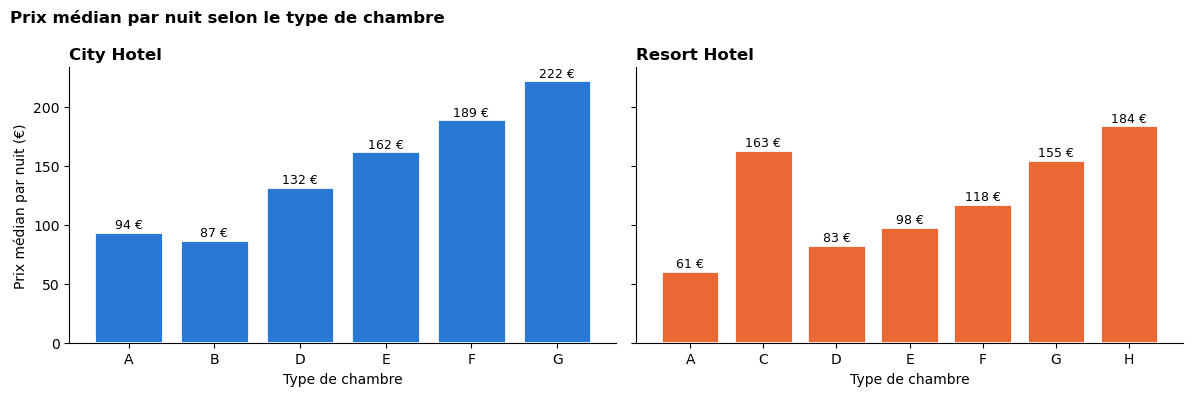

In [15]:
prix = (df_clean.groupby(['hotel', 'reserved_room_type'])['adr']
        .agg(nb='size', mediane='median').reset_index())
prix = prix[prix['nb'] >= 50]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (hotel, d) in zip(axes, prix.groupby('hotel')):
    ax.bar(d['reserved_room_type'], d['mediane'], color=COULEURS[hotel], edgecolor='white', linewidth=2)
    for x, y in zip(d['reserved_room_type'], d['mediane']):
        ax.text(x, y + 3, f'{y:.0f} €', ha='center', fontsize=9)
    ax.set_title(hotel, loc='left', fontweight='bold')
    ax.set_xlabel('Type de chambre')
axes[0].set_ylabel('Prix médian par nuit (€)')
fig.suptitle('Prix médian par nuit selon le type de chambre', x=0.01, ha='left', fontweight='bold')
sns.despine(); plt.tight_layout(); plt.savefig('fig_prix_chambres.png', dpi=150); plt.show()

**Pourquoi un seuil de 1 000 € ?** Le graphique montre qu'une seule valeur (5 400 €) se détache complètement. Le prix suivant n'est que de 510 €, soit 10 fois moins, et les suivants descendent progressivement jusqu'à 384 €. Le seuil de 1 000 € isole donc uniquement cette erreur, sans toucher aux prix élevés mais réalistes.
La méthode IQR (règle des « moustaches ») aurait classé environ 3 800 réservations comme aberrantes. Ce sont surtout de vraies grandes chambres en haute saison : nous ne l'avons donc pas appliquée.

**Prix par type de chambre :** au City Hotel, le prix médian augmente régulièrement de A (94 €) à G (222 €). Au Resort Hotel, la tendance est la même de A (61 €) à H (184 €), sauf la chambre C (163 €), plus chère que D, E et F. Les codes de chambre sont anonymisés : ils ne correspondent pas forcément à une gamme, ni à la même chambre d'un hôtel à l'autre.
La chambre A est la plus réservée et la moins chère dans les deux hôtels (médiane de 94 € et 61 €). Les 5 400 € supprimés représentaient donc environ 57 fois le prix normal : c'est bien une erreur. Les prix élevés, jusqu'à 510 €, restent plausibles et sont gardés.
Les types de chambre trop rares (moins de 50 réservations : C au City, B et L au Resort) ne sont pas affichés.

#  Les prix à 0 € : pourquoi on les garde

In [16]:
print("Réservations à 0 € :", (df_clean['adr'] == 0).sum())
df_clean.loc[df_clean['adr'] == 0, 'market_segment'].value_counts()

Réservations à 0 € : 1810


market_segment
Complementary    665
Online TA        319
Offline TA/TO    297
Groups           233
Direct           221
Corporate         71
Aviation           4
Name: count, dtype: int64

**Prix à 0 € :** 1 810 réservations (1,5 % du total). 665 sont des séjours offerts par l'hôtel (« Complementary »), ce qui explique le prix nul. Les autres sont réparties dans tous les segments : il peut s'agir de promotions, de compensations ou de prix non renseignés. Comme elles sont peu nombreuses et pas forcément fausses, elles sont gardées.

In [17]:
print(df['is_canceled'].value_counts(normalize=True).round(3))
print(df['hotel'].value_counts())

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


**Cible :** 37 % des réservations sont annulées et 63 % ne le sont pas. Les classes sont déséquilibrées, mais pas trop.
**Hôtels :** le City Hotel a 2 fois plus de réservations (79 330) que le Resort Hotel (40 060).

In [18]:
df.duplicated().sum()

np.int64(31994)

**Doublons :** 31 994 lignes identiques, soit 27 % du total. Le fichier n'a pas de numéro de réservation, donc ces lignes peuvent être de vraies réservations différentes (par exemple un groupe qui réserve plusieurs chambres pareilles). On les garde, sinon on fausse le taux d'annulation.

# Créer des colonnes utiles pour la suite

In [19]:
mois = {'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,'July':7,
        'August':8,'September':9,'October':10,'November':11,'December':12}
df_clean['arrival_month_num'] = df_clean['arrival_date_month'].map(mois)

df_clean['arrival_date'] = pd.to_datetime(dict(year=df_clean['arrival_date_year'],
                                               month=df_clean['arrival_month_num'],
                                               day=df_clean['arrival_date_day_of_month']))
df_clean['total_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'] + df_clean['babies']

df_clean[['arrival_date', 'arrival_month_num', 'total_nights', 'total_guests']].head()

,arrival_date,arrival_month_num,total_nights,total_guests
0,2015-07-01,7,0,2
1,2015-07-01,7,0,2
2,2015-07-01,7,1,1
3,2015-07-01,7,1,1
4,2015-07-01,7,2,2


# Vérifier que les dates sont bien de vraies dates

In [20]:
df_clean[['arrival_date', 'reservation_status_date']].dtypes

arrival_date               datetime64[ns]
reservation_status_date    datetime64[ns]
dtype: object

# Remettre les autres colonnes au bon type

In [21]:
# Mois dans l'ordre (janvier → décembre) pour les graphiques
ordre_mois = list(mois.keys())
df_clean['arrival_date_month'] = pd.Categorical(df_clean['arrival_date_month'],
                                                categories=ordre_mois, ordered=True)

# Colonnes oui/non (0/1) : on vérifie qu'elles ne contiennent que 0 et 1
for col in ['is_canceled', 'is_repeated_guest']:
    print(col, sorted(df_clean[col].unique()))

df_clean.dtypes

is_canceled [np.int64(0), np.int64(1)]
is_repeated_guest [np.int64(0), np.int64(1)]


hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                      category
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                   int64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                        object
assigned_room_type  

children, agent, company → int64 (et non plus float64)
arrival_date, reservation_status_date → datetime64[ns]
arrival_date_month → category

# afficher les dates en français

In [22]:
df_clean['arrival_date'].dt.strftime('%d/%m/%Y').head()

0    01/07/2015
1    01/07/2015
2    01/07/2015
3    01/07/2015
4    01/07/2015
Name: arrival_date, dtype: object

**Formats :** les dates (`arrival_date`, `reservation_status_date`) sont converties au format date standard AAAA-MM-JJ, compatible avec BigQuery. Les mois sont rangés dans l'ordre du calendrier, et `children`, `agent` et `company` sont passés en nombres entiers.

In [23]:
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
is_canceled,119208.0,0.370764,0.0,0.0,0.0,1.0,1.0,0.483011
lead_time,119208.0,104.109045,0.0,18.0,69.0,161.0,737.0,106.875835
arrival_date_year,119208.0,2016.156466,2015.0,2016.0,2016.0,2017.0,2017.0,0.707487
arrival_date_week_number,119208.0,27.163638,1.0,16.0,28.0,38.0,53.0,13.601068
arrival_date_day_of_month,119208.0,15.79873,1.0,8.0,16.0,23.0,31.0,8.781048
stays_in_weekend_nights,119208.0,0.927035,0.0,0.0,1.0,2.0,19.0,0.995082
stays_in_week_nights,119208.0,2.499178,0.0,1.0,2.0,3.0,50.0,1.89709
adults,119208.0,1.859204,0.0,2.0,2.0,2.0,55.0,0.57519
children,119208.0,0.104045,0.0,0.0,0.0,0.0,10.0,0.398839
babies,119208.0,0.007961,0.0,0.0,0.0,0.0,10.0,0.09751


In [24]:
(df_clean['adults'] == 0).sum()

np.int64(223)

**Réservations sans adulte :** 223 réservations contiennent seulement des enfants (0,2 %). C'est possible, par exemple une chambre séparée réservée pour les enfants d'une famille : on les garde.

## Étude des annulations.

# Cellule de préparation graphiques

In [25]:
sns.set_theme(style='whitegrid')
COULEURS = {'City Hotel': '#2a78d6', 'Resort Hotel': '#eb6834'}
MOY = df_clean['is_canceled'].mean() * 100

def taux_par_hotel(col, titre, fichier, ordre=None, horizontal=False, min_n=50):
    """Taux d'annulation par catégorie, comparé entre les deux hôtels."""
    t = df_clean.groupby([col, 'hotel'], observed=True)['is_canceled'].agg(['mean', 'size']).reset_index()
    t = t[t['size'] >= min_n]                      # on écarte les catégories trop petites
    taux = t.pivot(index=col, columns='hotel', values='mean').mul(100).round(1)
    nb = t.pivot(index=col, columns='hotel', values='size')
    if ordre is not None:
        taux = taux.reindex([o for o in ordre if o in taux.index])
    elif horizontal:
        taux = taux.loc[taux.mean(axis=1).sort_values(ascending=False).index]
    nb = nb.reindex(taux.index)

    ax = taux.plot(kind='barh' if horizontal else 'bar', color=[COULEURS[c] for c in taux.columns],
                   figsize=(10, 4.5), width=0.75, edgecolor='white', linewidth=2)
    if horizontal:
        ax.axvline(MOY, color='#555555', linestyle='--', linewidth=1.5, label=f'Moyenne ({MOY:.0f} %)')
        ax.set_xlabel("Taux d'annulation (%)"); ax.set_ylabel(''); ax.invert_yaxis()
    else:
        ax.axhline(MOY, color='#555555', linestyle='--', linewidth=1.5, label=f'Moyenne ({MOY:.0f} %)')
        ax.set_ylabel("Taux d'annulation (%)"); ax.set_xlabel(''); plt.xticks(rotation=0)
    ax.set_title(titre, loc='left', fontweight='bold')
    ax.legend(frameon=False)
    sns.despine()
    plt.tight_layout(); plt.savefig(fichier, dpi=150, bbox_inches='tight'); plt.show()
    return taux.join(nb, lsuffix=' (%)', rsuffix=' (nb)')

# Par établissement

In [26]:
par_hotel = df_clean.groupby('hotel').agg(
    reservations=('is_canceled', 'size'),
    annulations=('is_canceled', 'sum'),
    taux_annulation=('is_canceled', 'mean')
)
par_hotel['taux_annulation'] = (par_hotel['taux_annulation'] * 100).round(1)
par_hotel

,reservations,annulations,taux_annulation
hotel,,,
City Hotel,79162,33078,41.8
Resort Hotel,40046,11120,27.8


**Par établissement :** le City Hotel annule beaucoup plus que le Resort Hotel : **41,8 %** contre **27,8 %**, soit 14 points d'écart.
Le City Hotel concentre aussi 3 annulations sur 4 (33 078 sur 44 198). C'est l'établissement où l'enjeu est le plus fort.

###  Volume et taux d'annulation par hôtel

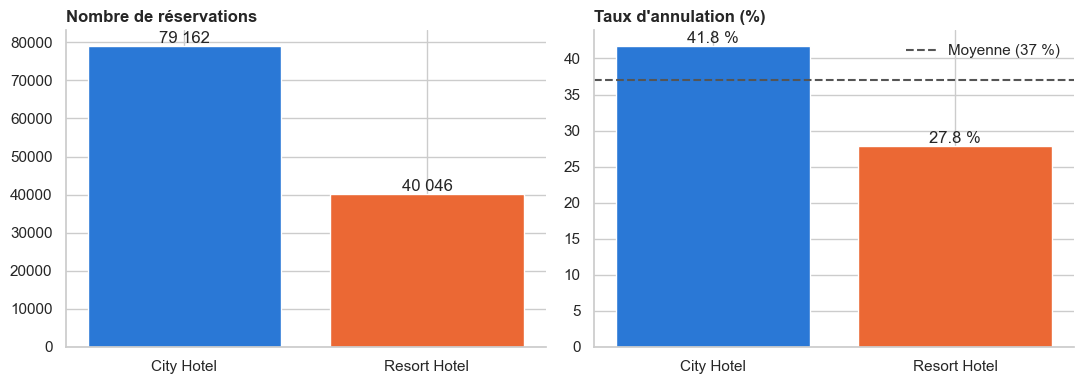

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
vol = df_clean['hotel'].value_counts()
tx = df_clean.groupby('hotel')['is_canceled'].mean().mul(100).round(1).reindex(vol.index)
axes[0].bar(vol.index, vol.values, color=[COULEURS[h] for h in vol.index])
axes[0].set_title('Nombre de réservations', loc='left', fontweight='bold')
axes[1].bar(tx.index, tx.values, color=[COULEURS[h] for h in tx.index])
axes[1].axhline(MOY, color='#555555', linestyle='--', label=f'Moyenne ({MOY:.0f} %)')
axes[1].set_title("Taux d'annulation (%)", loc='left', fontweight='bold')
axes[1].legend(frameon=False)
for i, v in enumerate(vol):
    axes[0].text(i, v, f'{v:,}'.replace(',', ' '), ha='center', va='bottom')
for i, v in enumerate(tx):
    axes[1].text(i, v, f'{v} %', ha='center', va='bottom')
sns.despine(); plt.tight_layout(); plt.savefig('fig1_hotels.png', dpi=150); plt.show()

**Constat :** le City Hotel reçoit **2 fois plus de réservations** que le Resort Hotel (79 162 contre 40 046), mais ce n'est pas la seule raison de ses nombreuses annulations : son **taux** est aussi bien plus élevé (**41,8 %** contre **27,8 %**, au-dessus de la moyenne de 37 %). Le City Hotel annule donc plus **en nombre ET en proportion** : c'est l'établissement le plus exposé.

# Graphique 2 : saisonnalité par mois d’arrivée

### 2. Taux d'annulation selon le mois d'arrivée

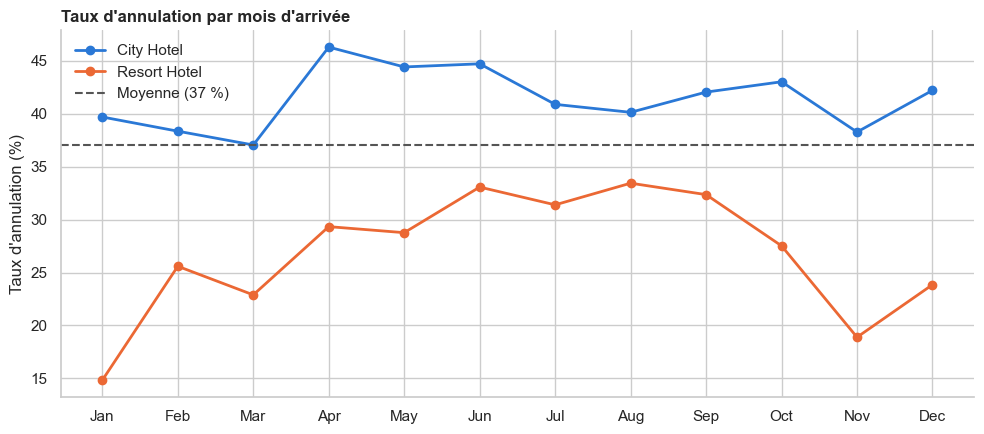

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,39.7,14.8
February,38.4,25.6
March,37.1,22.9
April,46.3,29.3
May,44.4,28.8
June,44.7,33.1
July,40.9,31.4
August,40.1,33.4
September,42.1,32.4


In [28]:
mensuel = df_clean.groupby(['arrival_date_month', 'hotel'], observed=True)['is_canceled'].mean().mul(100).unstack()
ax = mensuel.plot(marker='o', linewidth=2, color=[COULEURS[c] for c in mensuel.columns], figsize=(10, 4.5))
ax.axhline(MOY, color='#555555', linestyle='--', linewidth=1.5, label=f'Moyenne ({MOY:.0f} %)')
ax.set_title("Taux d'annulation par mois d'arrivée", loc='left', fontweight='bold')
ax.set_ylabel("Taux d'annulation (%)"); ax.set_xlabel('')
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in mensuel.index])
ax.legend(frameon=False); sns.despine()
plt.tight_layout(); plt.savefig('fig2_mois.png', dpi=150); plt.show()
mensuel.round(1)

**Constat : deux profils saisonniers différents.**
- **City Hotel :** le taux reste **au-dessus de la moyenne toute l'année** (entre 37 % et 46 %). Il est le plus élevé au **printemps** (avril : 46 %, mai-juin : environ 44 %). Le risque est donc permanent, quelle que soit la saison.
- **Resort Hotel :** le taux suit la **saison touristique**. Il est faible en hiver (janvier : 15 %, novembre : 19 %) et monte en **été** (juin-septembre : 31 % à 33 %), quand la demande est forte et que les clients réservent longtemps à l'avance.
- Le Resort Hotel reste **sous la moyenne tous les mois**.

→ Au Resort Hotel, la vigilance doit porter sur les **mois d'été** ; au City Hotel, elle doit être **constante**, avec un pic au printemps.

# Graphique 3 : évolution de juillet 2015 à août 2017

### 3. Évolution du taux d'annulation dans le temps

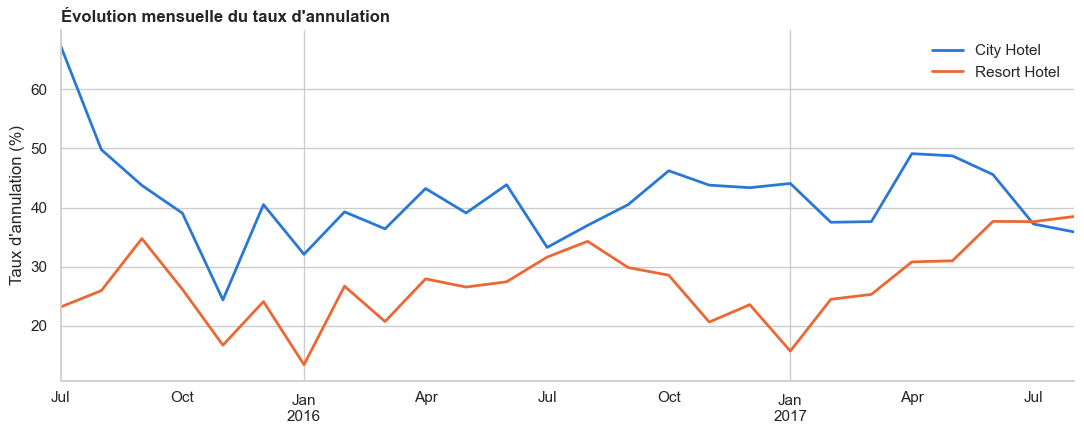

In [29]:
evol = df_clean.groupby([df_clean['arrival_date'].dt.to_period('M'), 'hotel'])['is_canceled'].mean().mul(100).unstack()
evol.index = evol.index.to_timestamp()
ax = evol.plot(linewidth=2, color=[COULEURS[c] for c in evol.columns], figsize=(11, 4.5))
ax.set_title("Évolution mensuelle du taux d'annulation", loc='left', fontweight='bold')
ax.set_ylabel("Taux d'annulation (%)"); ax.set_xlabel('')
ax.legend(frameon=False); sns.despine()
plt.tight_layout(); plt.savefig('fig3_evolution.png', dpi=150); plt.show()

**Constat :**
- **City Hotel :** le taux est très élevé au début des données (67 % en juillet 2015), puis se stabilise **entre 35 % et 50 %**, avec des pics au printemps 2016 et 2017. Le point de départ très élevé est à interpréter avec prudence : il correspond au début de la collecte des données.
- **Resort Hotel :** le taux suit un rythme saisonnier régulier, avec des creux chaque hiver (environ 13 % en janvier 2016, 16 % en janvier 2017). Surtout, il **augmente nettement en 2017**, jusqu'à environ 38 %, au point de **dépasser le City Hotel en juillet-août 2017**.

→ L'écart entre les deux hôtels se réduit en 2017 : la hausse des annulations au Resort Hotel est un **signal d'alerte** à surveiller.

### 4. Taux d'annulation selon le délai de réservation

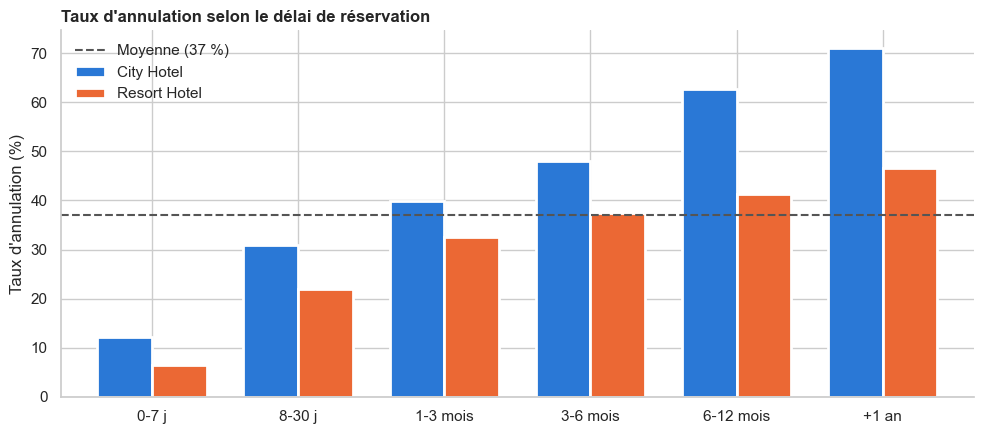

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
lead_time_tranche,,,,
0-7 j,12.2,6.5,10703,8932
8-30 j,30.9,21.9,12541,6404
1-3 mois,39.9,32.5,20775,8753
3-6 mois,48.0,37.4,18206,8214
6-12 mois,62.7,41.3,14234,7299
+1 an,71.1,46.6,2703,444


In [30]:
df_clean['lead_time_tranche'] = pd.cut(df_clean['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                                       labels=['0-7 j', '8-30 j', '1-3 mois', '3-6 mois', '6-12 mois', '+1 an'])
taux_par_hotel('lead_time_tranche', "Taux d'annulation selon le délai de réservation", 'fig4_delai.png')

**Constat : plus on réserve longtemps à l'avance, plus on annule.** C'est vrai dans les deux hôtels, et la progression est régulière.
- Réservé **moins d'une semaine avant** : très peu d'annulations (12 % au City Hotel, environ 6 % au Resort Hotel).
- Réservé **plus d'un an avant** : **71 %** d'annulations au City Hotel et environ 46 % au Resort Hotel.
- Au City Hotel, le taux dépasse la moyenne dès **1 à 3 mois** d'avance ; au Resort Hotel, à partir de **3 à 6 mois**.

→ Le délai de réservation est **l'un des facteurs les plus liés à l'annulation**. C'est logique : plus l'arrivée est lointaine, plus le client a le temps de changer de plan ou de trouver une meilleure offre. Cette variable, connue au moment de la réservation, sera **très utile pour le modèle**.

### 5. Taux d'annulation selon le type d'acompte

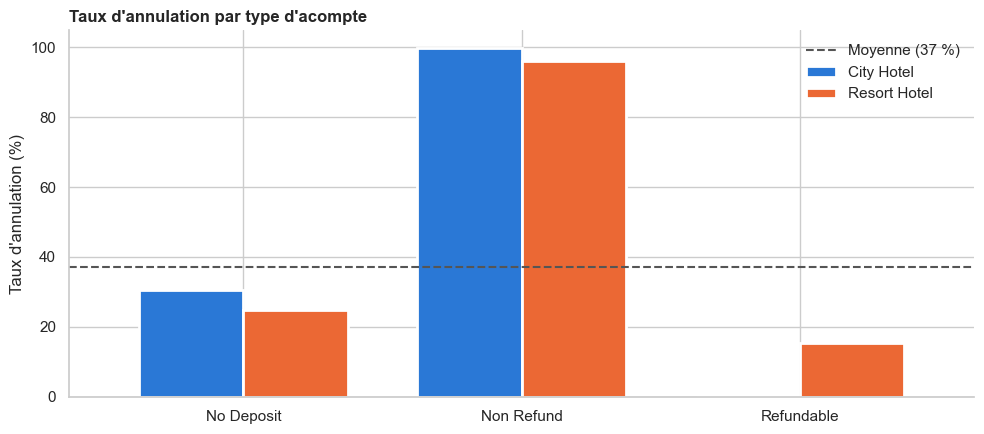

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
deposit_type,,,,
No Deposit,30.5,24.7,66275.0,38185.0
Non Refund,99.8,96.0,12867.0,1719.0
Refundable,NaN,15.5,NaN,142.0


In [31]:
taux_par_hotel('deposit_type', "Taux d'annulation par type d'acompte", 'fig5_acompte.png')

**Constat : un résultat surprenant.**
- **Sans acompte** (« No Deposit », 88 % des réservations) : 30,5 % d'annulations au City Hotel, 24,7 % au Resort Hotel.
- **Acompte non remboursable** (« Non Refund ») : **99,8 %** d'annulations au City Hotel et **96 %** au Resort Hotel.
- **Acompte remboursable** : seulement 142 réservations au Resort Hotel (15,5 %), et trop peu au City Hotel pour être affiché.

**Ce paradoxe s'explique probablement** par le fait que ces réservations non remboursables sont surtout des **réservations de groupe ou d'agences**, qui bloquent des chambres à l'avance puis les libèrent. Les données ne permettent pas de le vérifier précisément. Ce résultat est donc à interpréter avec **prudence** : il ne faut pas en conclure qu'un acompte non remboursable « provoque » des annulations.

### 6. Taux d'annulation selon le segment de marché

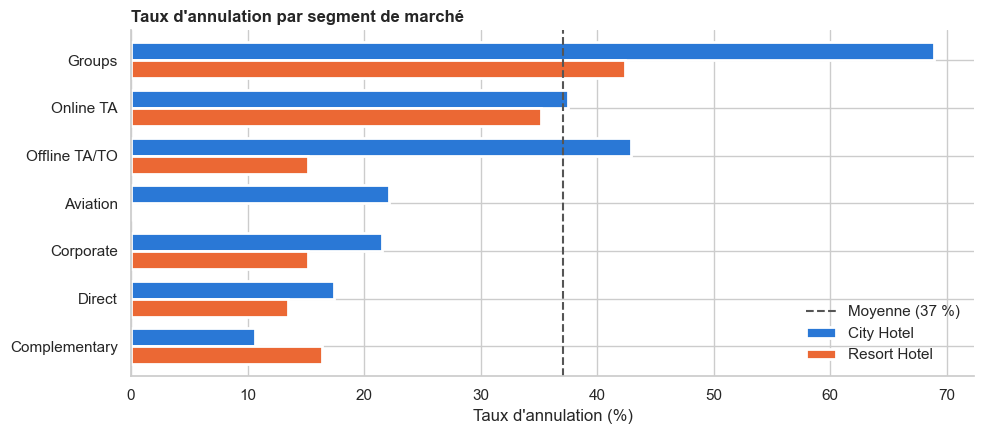

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
market_segment,,,,
Groups,68.9,42.4,13959.0,5831.0
Online TA,37.5,35.2,38679.0,17729.0
Offline TA/TO,42.9,15.2,16711.0,7470.0
Aviation,22.1,NaN,235.0,NaN
Corporate,21.5,15.2,2977.0,2305.0
Direct,17.4,13.5,6072.0,6510.0
Complementary,10.6,16.4,527.0,201.0


In [32]:
taux_par_hotel('market_segment', "Taux d'annulation par segment de marché", 'fig6_segment.png',
               horizontal=True, min_n=100)

**Constat :**
- **Groupes** : le segment le plus risqué dans les deux hôtels, surtout au City Hotel (**68,9 %** contre 42,4 %).
- **Agences en ligne** (Online TA) : le plus gros volume (56 408 réservations), avec un taux proche de la moyenne et **identique dans les deux hôtels** (environ 36 %).
- **Agences hors ligne** (Offline TA/TO) : **le plus grand écart entre les deux hôtels**, 42,9 % au City Hotel contre seulement 15,2 % au Resort Hotel.
- **Clients directs, entreprises et séjours offerts** : moins de 22 % d'annulations, ce sont les clients les plus fiables.
- Le segment **Aviation** (équipages) n'existe qu'au City Hotel.

→ Au City Hotel, les **groupes** et les **agences hors ligne** sont les priorités. Au Resort Hotel, ce sont les **groupes** et les **agences en ligne**.

### 7. Taux d'annulation selon le type de client

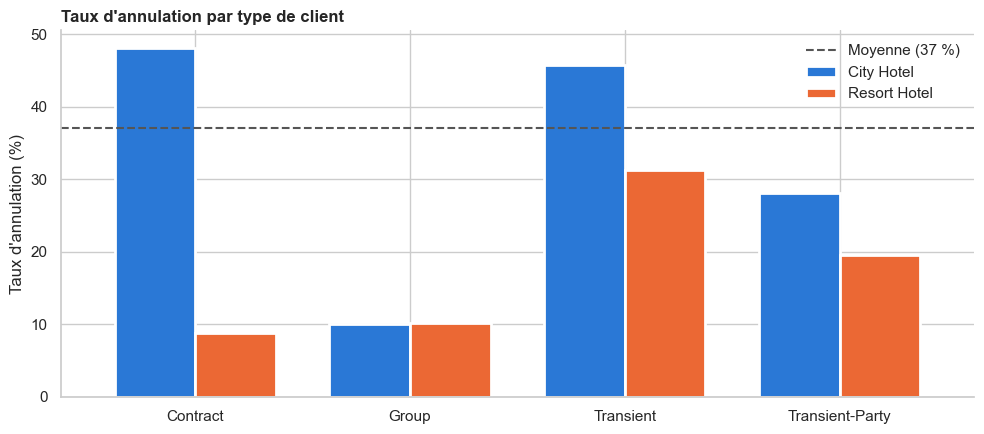

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
customer_type,,,,
Contract,48.1,8.8,2296,1776
Group,10.0,10.2,291,283
Transient,45.7,31.2,59271,30204
Transient-Party,28.1,19.5,17304,7783


In [33]:
taux_par_hotel('customer_type', "Taux d'annulation par type de client", 'fig7_type_client.png')

**Constat :**
- **Transient** (client individuel, la grande majorité des réservations) : environ 46 % d'annulations au City Hotel, contre 31 % au Resort Hotel.
- **Contract** (contrat avec une entreprise ou une agence) : **le plus grand écart**, environ 48 % au City Hotel contre seulement 9 % au Resort Hotel.
- **Group** : environ 10 % dans les deux hôtels.
- **Transient-Party** (individuels liés à un groupe) : environ 28 % au City Hotel et 20 % au Resort Hotel.

→ Le City Hotel annule plus pour presque tous les types de clients. Les clients sous contrat sont fiables au Resort Hotel, mais pas au City Hotel.

### 8. Taux d'annulation selon l'historique du client

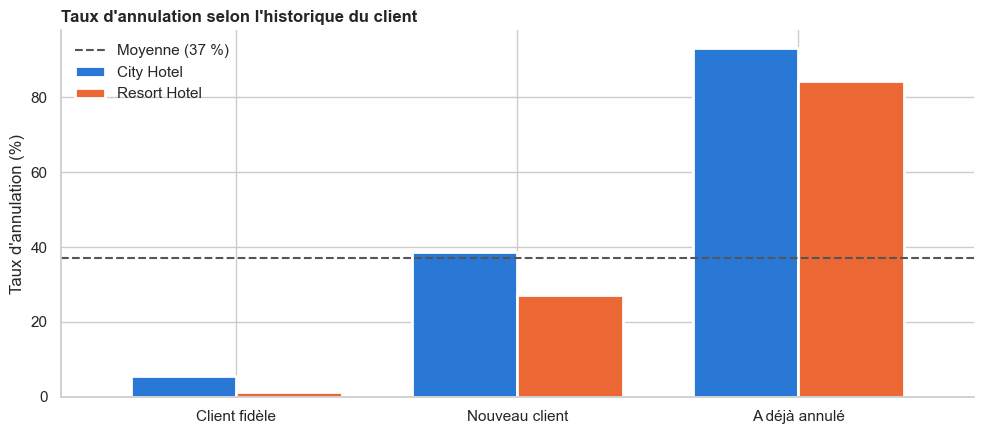

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
historique,,,,
Client fidèle,5.6,1.3,1240,1592
Nouveau client,38.6,27.2,72538,37359
A déjà annulé,93.2,84.4,5384,1095


In [34]:
df_clean['historique'] = np.select(
    [df_clean['previous_cancellations'] > 0, df_clean['is_repeated_guest'] == 1],
    ['A déjà annulé', 'Client fidèle'], default='Nouveau client')
taux_par_hotel('historique', "Taux d'annulation selon l'historique du client", 'fig8_historique.png',
               ordre=['Client fidèle', 'Nouveau client', 'A déjà annulé'])

**Constat : le passé du client est le signal le plus fort.**
- **A déjà annulé** : environ **93 %** d'annulations au City Hotel et 84 % au Resort Hotel.
- **Nouveau client** : proche de la moyenne (environ 38 % au City Hotel, 27 % au Resort Hotel).
- **Client fidèle** : presque aucune annulation (environ 5 % au City Hotel, 1 % au Resort Hotel).

→ Un client qui a déjà annulé recommencera très probablement. Un client fidèle vient presque toujours. Cette information est connue au moment de la réservation, donc **utilisable par le modèle**.

### 9. Taux d'annulation selon le nombre de demandes spéciales

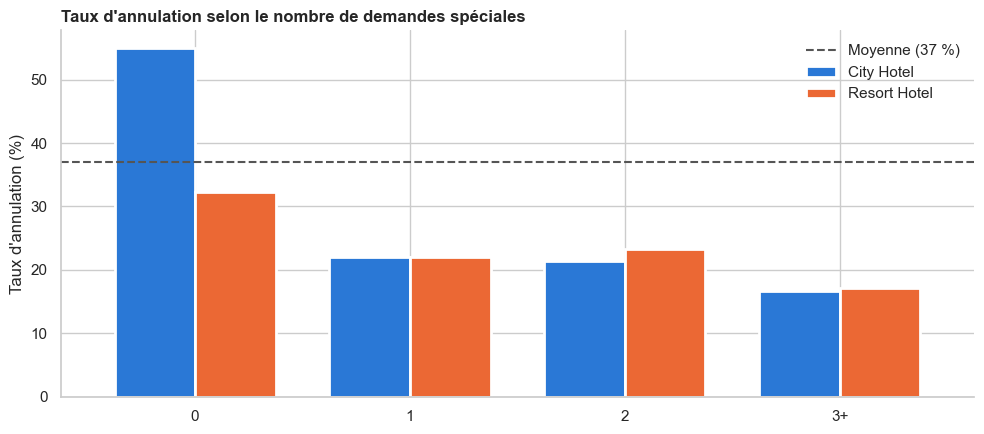

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
nb_demandes,,,,
0,55.0,32.3,47852,22347
1,22.1,22.0,21377,11806
2,21.4,23.3,8125,4827
3+,16.6,17.1,1808,1066


In [35]:
df_clean['nb_demandes'] = df_clean['total_of_special_requests'].clip(upper=3).astype(str).replace('3', '3+')
taux_par_hotel('nb_demandes', "Taux d'annulation selon le nombre de demandes spéciales", 'fig9_demandes.png',
               ordre=['0', '1', '2', '3+'])

**Constat :**
- **Aucune demande** : 55 % d'annulations au City Hotel, 32,3 % au Resort Hotel.
- **Dès 1 demande** : le taux tombe à environ **22 % dans les deux hôtels**.
- **3 demandes ou plus** : environ 17 %.

→ Un client qui fait une demande (lit bébé, étage, vue…) est **impliqué dans son séjour** et annule moins. Au City Hotel, une réservation sans demande annule 2,5 fois plus.
⚠️ Ces demandes peuvent être ajoutées **après** la réservation : à discuter avant de les utiliser dans le modèle.

# 2. Par segment de marché

In [36]:
par_segment = df_clean.groupby('market_segment').agg(
    reservations=('is_canceled', 'size'),
    taux_annulation=('is_canceled', 'mean')
)
par_segment['taux_annulation'] = (par_segment['taux_annulation'] * 100).round(1)
par_segment.sort_values('taux_annulation', ascending=False)

,reservations,taux_annulation
market_segment,,
Undefined,2,100.0
Groups,19790,61.1
Online TA,56408,36.8
Offline TA/TO,24181,34.3
Aviation,235,22.1
Corporate,5282,18.8
Direct,12582,15.4
Complementary,728,12.2


**Par segment de marché :**
- Les **groupes** annulent le plus : **61,1 %**, presque 2 fois la moyenne.
- Les **agences de voyage** (en ligne 36,8 %, hors ligne 34,3 %) sont proches de la moyenne, mais représentent le plus gros volume (plus de 80 000 réservations).
- Les clients **directs** (15,4 %), **entreprises** (18,8 %) et **séjours offerts** (12,2 %) annulent peu : ce sont les clients les plus fiables.
- Le segment « Undefined » ne compte que 2 réservations : on ne l'interprète pas.

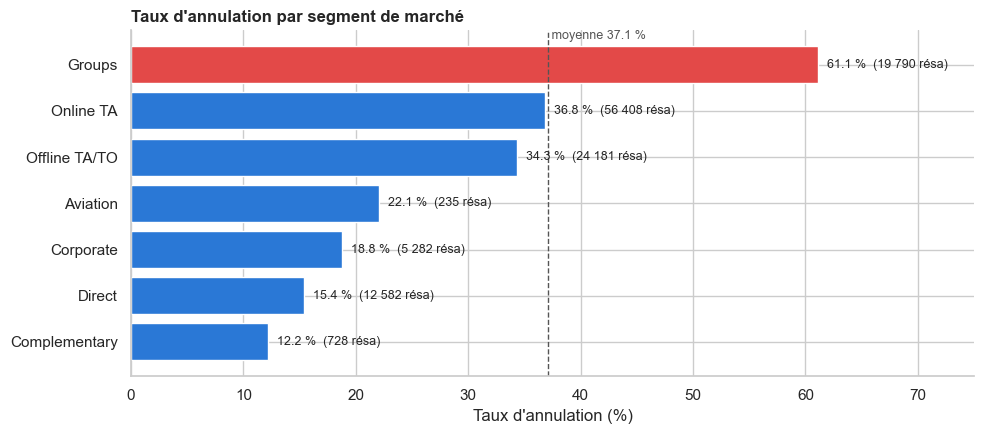

In [37]:
seg = par_segment[par_segment['reservations'] >= 100].sort_values('taux_annulation')
moy = df_clean['is_canceled'].mean() * 100
couleurs = ['#e34948' if t > moy else '#2a78d6' for t in seg['taux_annulation']]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(seg.index, seg['taux_annulation'], color=couleurs)
ax.axvline(moy, color='#555555', linestyle='--', linewidth=1)
ax.text(moy, len(seg) - 0.45, f' moyenne {moy:.1f} %', color='#555555', fontsize=9)
for i, (t, n) in enumerate(zip(seg['taux_annulation'], seg['reservations'])):
    ax.text(t + 0.8, i, f"{t} %  ({n:,} résa)".replace(',', ' '), va='center', fontsize=9)

ax.set_xlabel("Taux d'annulation (%)")
ax.set_xlim(0, 75)
ax.set_title("Taux d'annulation par segment de marché", loc='left', fontweight='bold')
sns.despine()
plt.tight_layout()
plt.savefig('fig_segment_global.png', dpi=150, bbox_inches='tight')
plt.show()

→ Le graphique 6 détaille ces segments **hôtel par hôtel** : l'écart le plus fort concerne les agences hors ligne (42,9 % au City Hotel contre 15,2 % au Resort Hotel).

# 3  Détail des taux par segment et par hôtel

In [38]:
seg_hotel = pd.crosstab(df_clean['market_segment'], df_clean['hotel'],
                        values=df_clean['is_canceled'], aggfunc='mean').mul(100).round(1)
seg_hotel

hotel,City Hotel,Resort Hotel
market_segment,,
Aviation,22.1,NaN
Complementary,10.6,16.4
Corporate,21.5,15.2
Direct,17.4,13.5
Groups,68.9,42.4
Offline TA/TO,42.9,15.2
Online TA,37.5,35.2
Undefined,100.0,NaN


Le segment « Undefined » (2 réservations seulement) n'est pas interprété.

### Vérification des prix aberrants
On affiche les 2 réservations dont le prix par nuit (`adr`) est négatif ou supérieur à 1 000 €, pour vérifier qu'il s'agit bien d'erreurs avant de les supprimer.



In [39]:
cols = ['hotel', 'is_canceled', 'reserved_room_type', 'adults', 'stays_in_weekend_nights',
        'stays_in_week_nights', 'adr', 'arrival_date_month', 'arrival_date_year', 'market_segment']
df.loc[(df['adr'] < 0) | (df['adr'] > 1000), cols]

,hotel,is_canceled,reserved_room_type,adults,stays_in_weekend_nights,stays_in_week_nights,adr,arrival_date_month,arrival_date_year,market_segment
14969,Resort Hotel,0,A,2,4,6,-6.38,March,2017,Groups
48515,City Hotel,1,A,2,0,1,5400.00,March,2016,Offline TA/TO


**Constat :** les 2 lignes sont bien des erreurs de saisie.
- **5 400 €** pour **1 nuit** en chambre A (la moins chère) au City Hotel, alors que le prix médian de cette chambre est de 94 €. La réservation a d'ailleurs été annulée.
- **-6,38 €** pour un séjour de 10 nuits d'un groupe au Resort Hotel : un prix négatif est impossible.

→ Ces 2 lignes sont supprimées.

# Qualité des données : graphique des valeurs manquantes

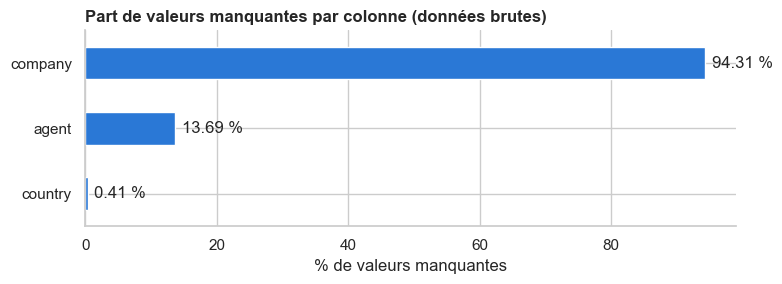

In [40]:
manq = (df.isna().mean() * 100).round(2)
manq = manq[manq > 0].sort_values()
ax = manq.plot(kind='barh', color='#2a78d6', figsize=(8, 3))
for i, v in enumerate(manq):
    ax.text(v + 1, i, f'{v} %', va='center')
ax.set_title('Part de valeurs manquantes par colonne (données brutes)', loc='left', fontweight='bold')
ax.set_xlabel('% de valeurs manquantes')
sns.despine(); plt.tight_layout(); plt.savefig('fig0_manquants.png', dpi=150); plt.show()

# Les deux hôtels : volume ET taux (deux graphiques côte à côte)

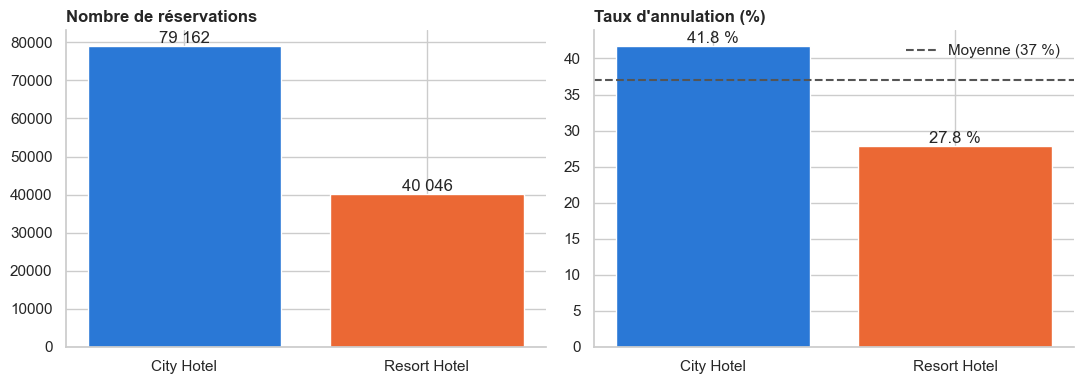

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
vol = df_clean['hotel'].value_counts()
tx = df_clean.groupby('hotel')['is_canceled'].mean().mul(100).round(1).reindex(vol.index)
axes[0].bar(vol.index, vol.values, color=[COULEURS[h] for h in vol.index])
axes[0].set_title('Nombre de réservations', loc='left', fontweight='bold')
axes[1].bar(tx.index, tx.values, color=[COULEURS[h] for h in tx.index])
axes[1].axhline(MOY, color='#555555', linestyle='--', label=f'Moyenne ({MOY:.0f} %)')
axes[1].set_title("Taux d'annulation (%)", loc='left', fontweight='bold'); axes[1].legend(frameon=False)
for ax, serie in zip(axes, [vol, tx]):
    for i, v in enumerate(serie):
        ax.text(i, v, f'{v:,.0f}'.replace(',', ' ') if serie is vol else f'{v} %', ha='center', va='bottom')
sns.despine(); plt.tight_layout(); plt.savefig('fig1_hotels.png', dpi=150); plt.show()

# Saisonnalité : taux par mois d’arrivée

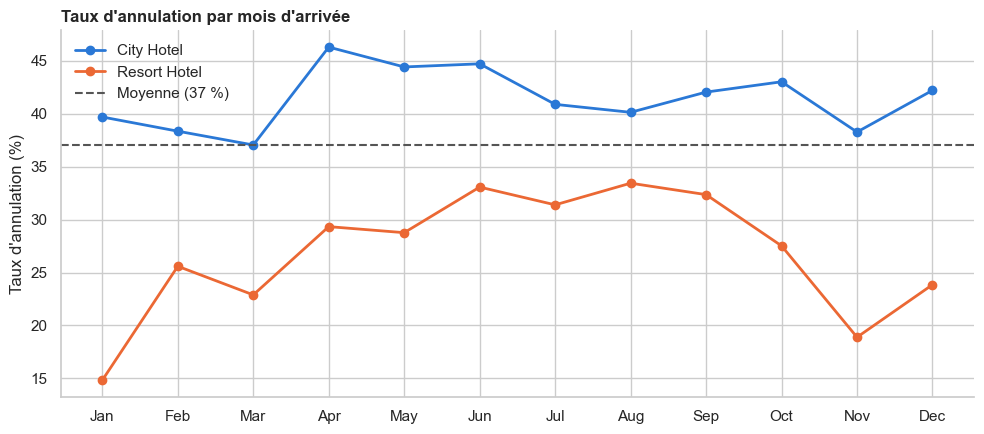

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,39.7,14.8
February,38.4,25.6
March,37.1,22.9
April,46.3,29.3
May,44.4,28.8
June,44.7,33.1
July,40.9,31.4
August,40.1,33.4
September,42.1,32.4


In [42]:
mensuel = df_clean.groupby(['arrival_date_month', 'hotel'], observed=True)['is_canceled'].mean().mul(100).unstack()
ax = mensuel.plot(marker='o', linewidth=2, color=[COULEURS[c] for c in mensuel.columns], figsize=(10, 4.5))
ax.axhline(MOY, color='#555555', linestyle='--', linewidth=1.5, label=f'Moyenne ({MOY:.0f} %)')
ax.set_title("Taux d'annulation par mois d'arrivée", loc='left', fontweight='bold')
ax.set_ylabel("Taux d'annulation (%)"); ax.set_xlabel('')
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in mensuel.index])
ax.legend(frameon=False); sns.despine()
plt.tight_layout(); plt.savefig('fig2_mois.png', dpi=150); plt.show()
mensuel.round(1)

#  Prix de la nuit

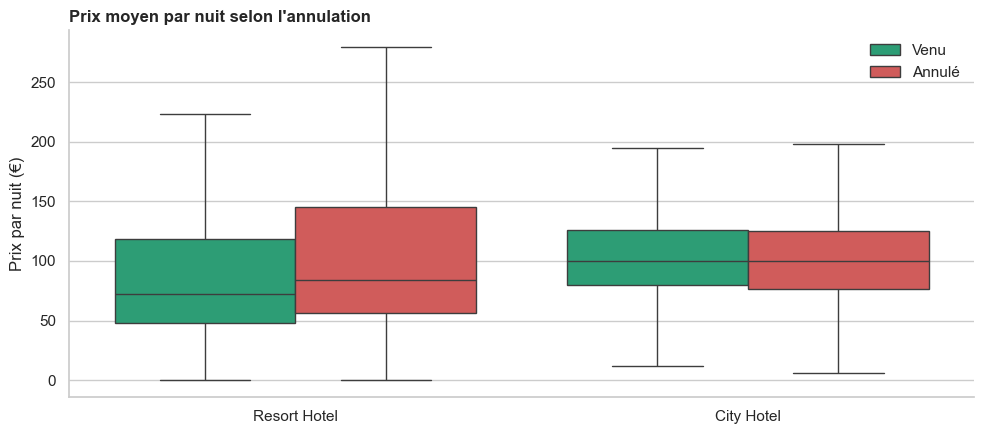

hotel         is_canceled
City Hotel    0              100.0
              1               99.9
Resort Hotel  0               72.0
              1               84.0
Name: adr, dtype: float64

In [43]:
plt.figure(figsize=(10, 4.5))
ax = sns.boxplot(data=df_clean, x='hotel', y='adr', hue='is_canceled', showfliers=False,
                 palette={0: '#1baf7a', 1: '#e34948'})
ax.set_title("Prix moyen par nuit selon l'annulation", loc='left', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('Prix par nuit (€)')
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Venu', 'Annulé'], frameon=False)
sns.despine(); plt.tight_layout(); plt.savefig('fig11_prix.png', dpi=150); plt.show()
df_clean.groupby(['hotel', 'is_canceled'])['adr'].median()

# Pays : top 10 par nombre de réservations

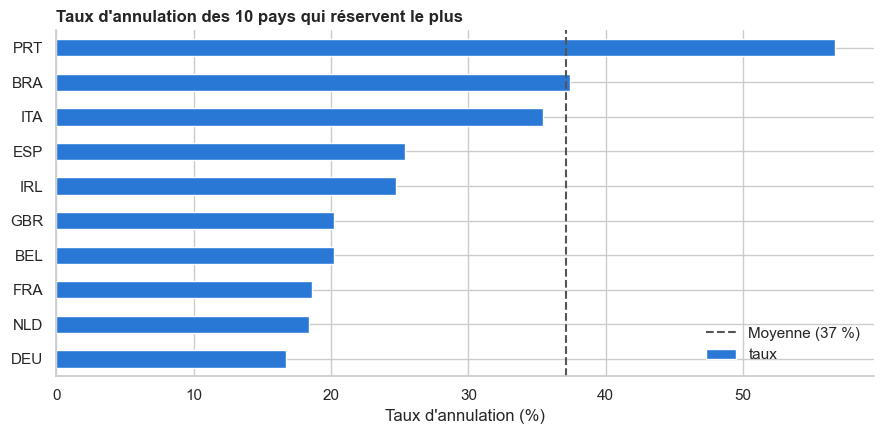

,taux,nb
country,,
PRT,56.7,48482
GBR,20.2,12119
FRA,18.6,10401
ESP,25.4,8560
DEU,16.7,7285
ITA,35.4,3761
IRL,24.7,3374
BEL,20.2,2342
BRA,37.4,2222


In [44]:
top10 = df_clean['country'].value_counts().head(10).index
pays = (df_clean[df_clean['country'].isin(top10)].groupby('country')['is_canceled']
        .agg(taux='mean', nb='size').assign(taux=lambda d: (d['taux'] * 100).round(1))
        .sort_values('taux'))
ax = pays['taux'].plot(kind='barh', color='#2a78d6', figsize=(9, 4.5))
ax.axvline(MOY, color='#555555', linestyle='--', label=f'Moyenne ({MOY:.0f} %)')
ax.set_title("Taux d'annulation des 10 pays qui réservent le plus", loc='left', fontweight='bold')
ax.set_xlabel("Taux d'annulation (%)"); ax.set_ylabel(''); ax.legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.savefig('fig12_pays.png', dpi=150); plt.show()
pays.sort_values('nb', ascending=False)

## Analyse approfondie des annulations
Pour chaque question, on compare le **taux d'annulation** des deux hôtels (City Hotel en bleu, Resort Hotel en orange). La ligne en pointillés indique la moyenne générale (37 %).

# Parking

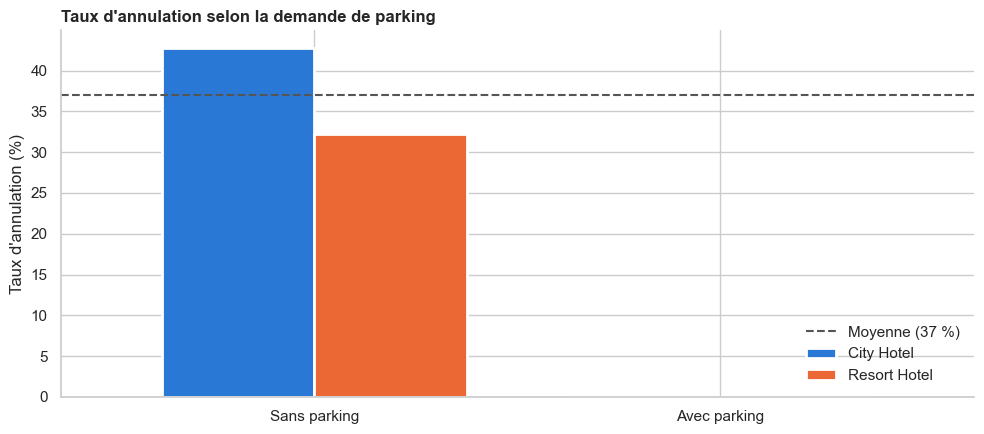

hotel,City Hotel (%),Resort Hotel (%),City Hotel (nb),Resort Hotel (nb)
parking,,,,
Sans parking,42.8,32.2,77242,34557
Avec parking,0.0,0.0,1920,5489


In [45]:
df_clean['parking'] = np.where(df_clean['required_car_parking_spaces'] > 0, 'Avec parking', 'Sans parking')
taux_par_hotel('parking', "Taux d'annulation selon la demande de parking", 'fig10_parking.png',
               ordre=['Sans parking', 'Avec parking'])

# Prix par nuit : réservations venues vs annulées

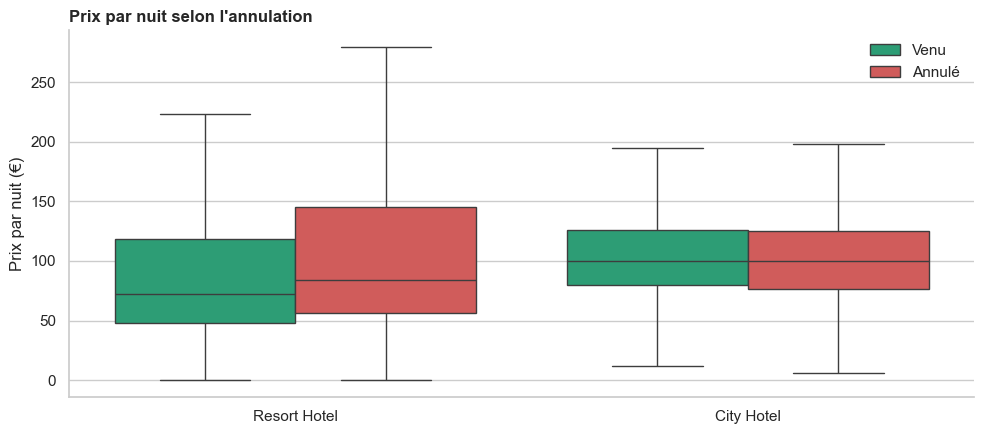

is_canceled,0,1
hotel,,
City Hotel,100.0,99.9
Resort Hotel,72.0,84.0


In [46]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df_clean, x='hotel', y='adr', hue='is_canceled',
            palette={0: '#1baf7a', 1: '#e34948'}, showfliers=False, ax=ax)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Venu', 'Annulé'], frameon=False)
ax.set_title("Prix par nuit selon l'annulation", loc='left', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('Prix par nuit (€)')
sns.despine(); plt.tight_layout()
plt.savefig('fig11_prix_annulation.png', dpi=150, bbox_inches='tight'); plt.show()
df_clean.groupby(['hotel', 'is_canceled'])['adr'].median().unstack().round(1)

# Corrélations avec l’annulation

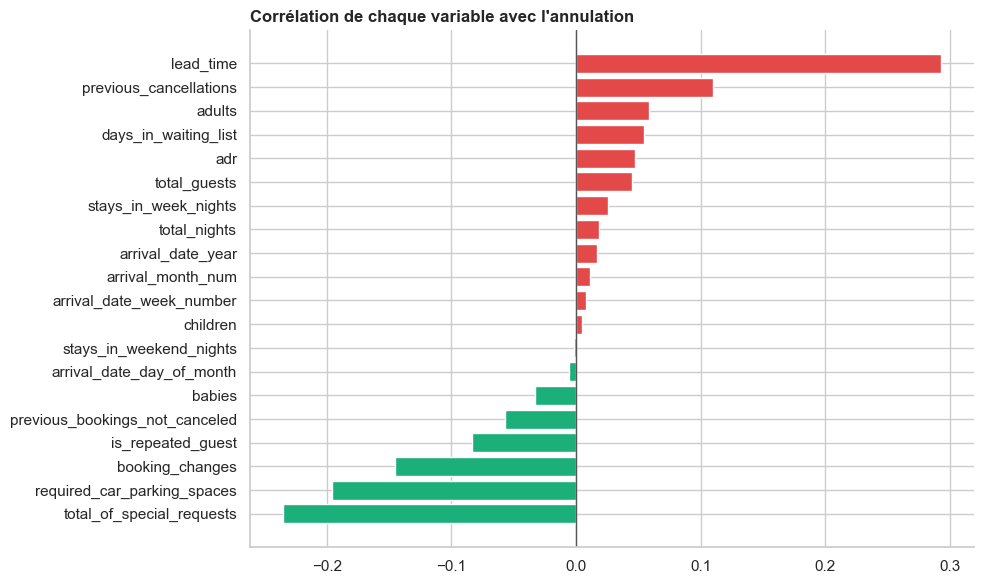

total_of_special_requests        -0.23
required_car_parking_spaces      -0.20
booking_changes                  -0.14
is_repeated_guest                -0.08
previous_bookings_not_canceled   -0.06
babies                           -0.03
arrival_date_day_of_month        -0.01
stays_in_weekend_nights          -0.00
children                          0.00
arrival_date_week_number          0.01
arrival_month_num                 0.01
arrival_date_year                 0.02
total_nights                      0.02
stays_in_week_nights              0.03
total_guests                      0.04
adr                               0.05
days_in_waiting_list              0.05
adults                            0.06
previous_cancellations            0.11
lead_time                         0.29
Name: is_canceled, dtype: float64

In [47]:
corr = (df_clean.select_dtypes('number').drop(columns=['agent', 'company'])
        .corr()['is_canceled'].drop('is_canceled').sort_values())
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(corr.index, corr.values, color=['#e34948' if v > 0 else '#1baf7a' for v in corr.values])
ax.axvline(0, color='#555555', linewidth=1)
ax.set_title("Corrélation de chaque variable avec l'annulation", loc='left', fontweight='bold')
sns.despine(); plt.tight_layout()
plt.savefig('fig13_correlations.png', dpi=150, bbox_inches='tight'); plt.show()
corr.round(2)

# Synthèse : quelles variables sont liées à l’annulation ?

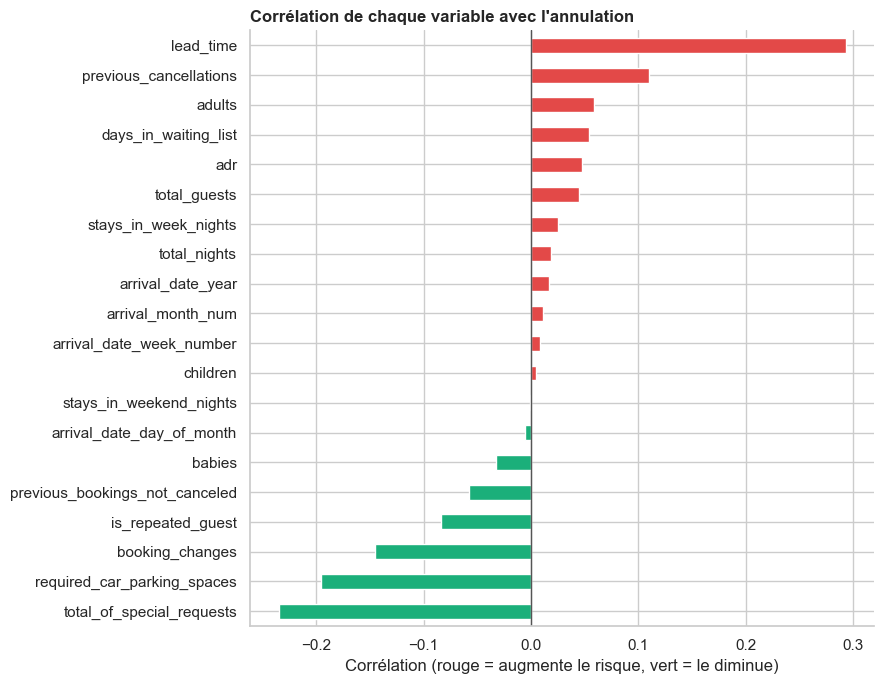

total_of_special_requests        -0.235
required_car_parking_spaces      -0.196
booking_changes                  -0.145
is_repeated_guest                -0.084
previous_bookings_not_canceled   -0.057
babies                           -0.033
arrival_date_day_of_month        -0.006
stays_in_weekend_nights          -0.001
children                          0.005
arrival_date_week_number          0.008
arrival_month_num                 0.011
arrival_date_year                 0.017
total_nights                      0.019
stays_in_week_nights              0.026
total_guests                      0.045
adr                               0.048
days_in_waiting_list              0.054
adults                            0.058
previous_cancellations            0.110
lead_time                         0.293
dtype: float64

In [48]:
num = df_clean.select_dtypes('number').drop(columns=['is_canceled', 'agent', 'company'])
corr = num.corrwith(df_clean['is_canceled']).sort_values()
ax = corr.plot(kind='barh', color=np.where(corr > 0, '#e34948', '#1baf7a'), figsize=(9, 7))
ax.axvline(0, color='#555555', linewidth=1)
ax.set_title("Corrélation de chaque variable avec l'annulation", loc='left', fontweight='bold')
ax.set_xlabel('Corrélation (rouge = augmente le risque, vert = le diminue)')
sns.despine(); plt.tight_layout(); plt.savefig('fig13_correlations.png', dpi=150); plt.show()
corr.round(3)

**Comparaison des deux hôtels par segment :**
- Le City Hotel annule plus dans **presque tous les segments**.
- Le plus gros écart concerne les **agences hors ligne** : **42,9 %** au City Hotel contre seulement **15,2 %** au Resort Hotel.
- Les **groupes** annulent beaucoup dans les deux hôtels, mais surtout au City Hotel (**68,9 %** contre 42,4 %).
- Les **agences en ligne** se comportent de la même façon dans les deux hôtels (environ 36 %).
- Le segment « Aviation » (équipages de compagnies aériennes) n'existe qu'au City Hotel, ce qui est logique pour un hôtel en ville.

**À retenir pour la direction :** les réservations de **groupe** et d'**agences hors ligne au City Hotel** sont les plus exposées à l'annulation. Ce sont des cibles prioritaires pour demander un acompte ou relancer le client.

**Fuite de données :** `reservation_status` correspond exactement à la cible. « Canceled » (42 992) et « No-Show » (1 206) donnent toujours `is_canceled = 1`, « Check-Out » (75 010) donne toujours 0.
Cette variable n'est connue qu'**après** l'arrivée prévue : si on la donnait au modèle, il « tricherait » avec 100 % de réussite. Elle sera donc **exclue du modèle**, tout comme `reservation_status_date`.
On remarque aussi que 1 206 annulations sont des **no-shows** : le client n'est pas venu, sans prévenir.

## Synthèse : principaux constats

1. **Le City Hotel annule beaucoup plus** : 41,8 % contre 27,8 % au Resort Hotel. Il concentre 3 annulations sur 4.
2. **La saison joue surtout au Resort Hotel** : 15 % en janvier, plus de 31 % en été. Le City Hotel reste au-dessus de la moyenne toute l'année (37 à 46 %).
3. **Plus on réserve tôt, plus on annule** : de 12 % (moins d'une semaine avant) à 71 % (plus d'un an avant) au City Hotel.
4. **Les acomptes non remboursables annulent presque tous** (99,8 % au City Hotel, 96 % au Resort Hotel), probablement à cause des réservations de groupes ou d'agences.
5. **Les groupes sont le segment le plus risqué** (68,9 % au City Hotel). Les agences hors ligne montrent le plus grand écart entre les deux hôtels (42,9 % contre 15,2 %).
6. **L'historique du client est le signal le plus fort** : environ 90 % d'annulations chez ceux qui ont déjà annulé, presque aucune chez les clients fidèles.
7. **Un client qui fait au moins une demande spéciale annule moins** : environ 22 % contre 55 % sans demande au City Hotel.

→ Pour le modèle, les variables les plus prometteuses sont le délai de réservation, le type d'acompte, le segment, l'historique du client et l'hôtel.

## Conclusion générale

### 1. Les données
Le jeu de données réunit **119 390 réservations** de deux hôtels portugais, un hôtel urbain (City Hotel) et un hôtel de vacances (Resort Hotel), pour des arrivées entre juillet 2015 et août 2017. **37 % des réservations sont annulées.**

### 2. Ce que nous avons vérifié
Avant de nettoyer, nous avons contrôlé la qualité des données sous quatre angles :
- **la structure** : dimensions, types de colonnes, signification des variables ;
- **les valeurs manquantes** : 4 colonnes concernées ;
- **les doublons** : 31 994 lignes identiques ;
- **les incohérences et valeurs extrêmes** : prix négatifs, réservations sans client, séjours de 0 nuit, valeurs très élevées.

### 3. Le nettoyage réalisé, et pourquoi

**Valeurs manquantes : remplacées, pas supprimées**
- `company` (94 % vide) et `agent` (14 % vide) : une case vide ne signifie pas une erreur, mais que la réservation s'est faite **sans entreprise** ou **sans agence**. Nous avons remplacé par 0 pour garder cette information.
- `country` (488 lignes) : remplacé par « Unknown ». Supprimer ces lignes aurait fait perdre des réservations pour une seule information manquante.
- `children` (4 lignes) : remplacé par 0, la valeur de loin la plus fréquente.

**Lignes incohérentes : supprimées (182 lignes, soit 0,15 %)**
- 180 réservations **sans aucun client** (0 adulte, 0 enfant, 0 bébé) : une réservation sans personne n'a pas de sens.
- 2 **prix aberrants** (un négatif, un supérieur à 1 000 €) : erreurs de saisie évidentes, qui auraient faussé les moyennes.

**Valeurs inhabituelles : conservées**
- 715 séjours de **0 nuit** : possibles locations à la journée (« day use »).
- 223 réservations **avec enfants mais sans adulte** : possible chambre séparée pour les enfants d'une famille.
- Valeurs extrêmes réalistes (jusqu'à 737 jours d'avance, 55 adultes pour un groupe, 69 nuits) : rares mais plausibles. Les supprimer aurait fait disparaître de vrais comportements, par exemple les groupes, qui annulent beaucoup.

**Doublons : conservés (31 994 lignes)**
C'est le choix le plus important. Le jeu de données ne contient **ni numéro de réservation ni identifiant client**. Deux lignes identiques peuvent donc être **deux vraies réservations différentes**, par exemple un groupe ou une agence qui réserve plusieurs chambres identiques le même jour. Les supprimer aurait fait passer le taux d'annulation de **37 % à environ 27 %** et aurait sous-estimé le problème, surtout pour les groupes.

**Harmonisation et formats**
- Repas « Undefined » regroupé avec « SC » (sans repas), qui a la même signification selon la documentation.
- Dates converties au format standard AAAA-MM-JJ, compatible avec BigQuery.
- Mois rangés dans l'ordre du calendrier ; `children`, `agent` et `company` passés en nombres entiers.

**Colonnes ajoutées**
- `arrival_date` : date d'arrivée complète, utile pour suivre l'évolution dans le temps.
- `arrival_month_num` : numéro du mois, pour trier correctement.
- `total_nights` et `total_guests` : durée du séjour et nombre de personnes, utiles pour l'analyse et le modèle.

**Résultat :** **119 208 réservations, 0 valeur manquante**, prêtes pour le SQL et le Machine Learning.

### 4. Ce qui était le plus important
- **Ne pas supprimer trop vite** : 99,85 % des données ont été conservées. Chaque suppression ou remplacement est justifié par le sens métier.
- **Repérer la fuite de données** : le tableau croisé montre que `reservation_status` correspond exactement à la cible (« Canceled » et « No-Show » = annulé, « Check-Out » = venu). Cette variable, ainsi que `reservation_status_date`, n'est connue qu'**après** l'arrivée prévue. Elle est gardée pour l'analyse, mais **sera exclue du modèle**, sinon il « tricherait ».
- **Comparer des taux et pas des volumes** : le City Hotel a 2 fois plus de réservations, donc forcément plus d'annulations. C'est le **taux** qui mesure le vrai risque.

### 5. Les principaux constats
- **Le City Hotel annule beaucoup plus** que le Resort Hotel (**41,8 %** contre **27,8 %**) et concentre 3 annulations sur 4.
- **Les groupes sont le segment le plus risqué** (61,1 % d'annulations), surtout au City Hotel (68,9 %).
- **Les agences hors ligne** posent un problème propre au City Hotel (42,9 % contre 15,2 % au Resort).
- **Les clients directs et les entreprises sont les plus fiables** (moins de 20 % d'annulations).

### 6. Pour la suite du projet
- Le fichier `hotel_bookings_clean.csv` est disponible dans le repo (`dataset/processed/`) pour l'**analyse SQL dans BigQuery** et le **modèle de prédiction**.
- Le modèle n'utilisera que les informations **connues au moment de la réservation**.
- Les premiers constats orientent déjà les recommandations : **surveiller en priorité les réservations de groupe et celles des agences au City Hotel**.

## Recommandations pour les établissements

1. **Contacter en priorité les 10 % de réservations les plus à risque**, repérées par le modèle (100 sur 1 000) : un appel ou un e-mail de confirmation quelques jours avant l'arrivée. Cela repère 2,9 fois plus d'annulations qu'un choix au hasard.
2. **Surveiller les réservations faites très longtemps à l'avance** (plus de 3 mois) : demander une confirmation intermédiaire, surtout au City Hotel où le taux dépasse 60 % au-delà de 6 mois.
3. **Encadrer les réservations de groupe et d'agences hors ligne au City Hotel** : date limite pour libérer les chambres non confirmées, acompte partiel.
4. **Fidéliser les clients réguliers** (moins de 5 % d'annulations) et **surveiller ceux qui ont déjà annulé** (près de 90 % de récidive).
5. **Au Resort Hotel, renforcer la vigilance en été** : les annulations y montent à plus de 30 %, et ont nettement augmenté en 2017.
6. **Ajuster la surréservation** selon l'hôtel et la saison, grâce aux probabilités d'annulation données par le modèle.

# Partie 2 : Machine Learning

# 03 — Classification : prédire les annulations tardives

**Moment de prédiction :** J-7 avant l'arrivée.  
**Population :** réservations encore actives à J-7 (faites au moins 7 jours avant l'arrivée et non annulées avant J-7).  
**Cible :** `is_canceled` (annulation ou no-show dans les 7 derniers jours).

In [49]:
import pandas as pd
import numpy as np

In [50]:
# Chargement du dataset nettoyé
URL = "../dataset/processed/hotel_bookings_clean.csv"

df = pd.read_csv(URL, parse_dates=["arrival_date", "reservation_status_date"])
print(df.shape)

(119208, 36)


In [51]:
# Nombre de jours entre l'annulation et l'arrivée
jours_avant_arrivee = (df["arrival_date"] - df["reservation_status_date"]).dt.days

# On garde : les réservations faites au moins 7 jours avant l'arrivée
#            ET (non annulées OU annulées moins de 7 jours avant l'arrivée)
masque_j7 = (df["lead_time"] >= 7) & ((df["is_canceled"] == 0) | (jours_avant_arrivee < 7))

df_j7 = df[masque_j7].copy()

print(f"Réservations actives à J-7 : {len(df_j7)}")
print(f"Taux d'annulation tardive : {df_j7['is_canceled'].mean():.1%}")

Réservations actives à J-7 : 62427
Taux d'annulation tardive : 6.4%


In [52]:
# Variables retirées (voir classement_variables_J7.xlsx)
fuites = ["reservation_status", "reservation_status_date", "assigned_room_type",
          "booking_changes", "required_car_parking_spaces", "total_of_special_requests",
          "country"]
non_exploitables = ["arrival_date_year", "arrival_date"]
redondances = ["arrival_month_num", "total_nights", "total_guests"]

a_retirer = fuites + non_exploitables + redondances

X = df_j7.drop(columns=a_retirer + ["is_canceled"])
y = df_j7["is_canceled"]

# agent et company sont des identifiants, pas des quantités : on les passe en texte
X["agent"] = X["agent"].astype(str)
X["company"] = X["company"].astype(str)

print(X.shape)
print(X.columns.tolist())

(62427, 23)
['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr']


In [53]:
# Split temporel : on entraîne sur le passé, on teste sur le "futur"
DATE_COUPURE = "2017-04-01"

est_test = df_j7["arrival_date"] >= DATE_COUPURE

X_train, X_test = X[~est_test], X[est_test]
y_train, y_test = y[~est_test], y[est_test]

print(f"Train : {len(X_train)} réservations ({len(X_train)/len(X):.1%}) — arrivées avant le {DATE_COUPURE}")
print(f"Test  : {len(X_test)} réservations ({len(X_test)/len(X):.1%}) — arrivées à partir du {DATE_COUPURE}")
print(f"Taux d'annulation — train : {y_train.mean():.1%} | test : {y_test.mean():.1%}")

Train : 47779 réservations (76.5%) — arrivées avant le 2017-04-01
Test  : 14648 réservations (23.5%) — arrivées à partir du 2017-04-01
Taux d'annulation — train : 7.2% | test : 3.8%


In [54]:
colonnes_cat = X.select_dtypes(include=["object", "string"]).columns.tolist()
colonnes_num = X.select_dtypes(include="number").columns.tolist()

print(f"{len(colonnes_cat)} catégorielles : {colonnes_cat}")
print(f"{len(colonnes_num)} numériques : {colonnes_num}")

10 catégorielles : ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'company', 'customer_type']
13 numériques : ['lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr']


In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

encodeur = OneHotEncoder(
    min_frequency=100,                      # modalités rares (< 100 réservations) regroupées
    handle_unknown="infrequent_if_exist",   # modalité inconnue au test -> classée "rare"
    sparse_output=False
)

# Pour la régression logistique : normalisation + encodage
preproc_logreg = ColumnTransformer([
    ("num", StandardScaler(), colonnes_num),
    ("cat", encodeur, colonnes_cat)
])

# Pour les arbres (Random Forest, Gradient Boosting) : encodage seulement
preproc_arbres = ColumnTransformer([
    ("num", "passthrough", colonnes_num),
    ("cat", encodeur, colonnes_cat)
])

# Vérification : fit sur le train UNIQUEMENT, puis transform sur le test
X_train_test = preproc_logreg.fit_transform(X_train)
X_test_test = preproc_logreg.transform(X_test)
print(X_train_test.shape, X_test_test.shape)

(47779, 119) (14648, 119)


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

modele_logreg = Pipeline([
    ("preproc", preproc_logreg),
    ("modele", LogisticRegression(max_iter=1000))
])

modele_logreg.fit(X_train, y_train)

,steps,"[('preproc', ...), ('modele', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [57]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

def evaluer(modele, nom):
    proba = modele.predict_proba(X_test)[:, 1]   # probabilité d'annulation
    pred = modele.predict(X_test)                # prédiction 0/1 (seuil 0,5)

    # Règle métier : les 10 % de réservations les plus risquées (100 sur 1 000)
    n_top = int(len(proba) * 0.10)
    top_10 = np.argsort(-proba)[:n_top]
    precision_top10 = y_test.iloc[top_10].mean()

    print(f"=== {nom} ===")
    print(classification_report(y_test, pred, digits=2, zero_division=0))
    print(f"ROC-AUC           : {roc_auc_score(y_test, proba):.3f}")
    print(f"PR-AUC            : {average_precision_score(y_test, proba):.3f}")
    print(f"Précision top 10 %: {precision_top10:.1%} (hasard : {y_test.mean():.1%})")

evaluer(modele_logreg, "Régression logistique")

=== Régression logistique ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     14086
           1       0.85      0.06      0.11       562

    accuracy                           0.96     14648
   macro avg       0.90      0.53      0.55     14648
weighted avg       0.96      0.96      0.95     14648

ROC-AUC           : 0.659
PR-AUC            : 0.141
Précision top 10 %: 10.5% (hasard : 3.8%)


In [58]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

modele_rf = Pipeline([
    ("preproc", preproc_arbres),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                      random_state=42, n_jobs=-1))
])

modele_gb = Pipeline([
    ("preproc", preproc_arbres),
    ("modele", HistGradientBoostingClassifier(random_state=42))
])

modele_rf.fit(X_train, y_train)
modele_gb.fit(X_train, y_train)

evaluer(modele_rf, "Random Forest")
evaluer(modele_gb, "Gradient Boosting")

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     14086
           1       1.00      0.05      0.09       562

    accuracy                           0.96     14648
   macro avg       0.98      0.52      0.53     14648
weighted avg       0.96      0.96      0.95     14648

ROC-AUC           : 0.681
PR-AUC            : 0.185
Précision top 10 %: 11.2% (hasard : 3.8%)


=== Gradient Boosting ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     14086
           1       0.84      0.07      0.14       562

    accuracy                           0.96     14648
   macro avg       0.90      0.54      0.56     14648
weighted avg       0.96      0.96      0.95     14648

ROC-AUC           : 0.663
PR-AUC            : 0.161
Précision top 10 %: 11.3% (hasard : 3.8%)


In [59]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# TimeSeriesSplit découpe dans l'ordre des lignes : il faut donc trier le train par date d'arrivée
ordre = df_j7.loc[X_train.index, "arrival_date"].sort_values(kind="stable").index
X_train_trie = X_train.loc[ordre]
y_train_trie = y_train.loc[ordre]

In [60]:
rf_a_optimiser = Pipeline([
    ("preproc", preproc_arbres),
    ("modele", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

grille = {
    "modele__max_depth": [10, 20, None],        # profondeur maximale des arbres
    "modele__min_samples_leaf": [5, 20, 50]     # taille minimale des feuilles
}

recherche = GridSearchCV(
    rf_a_optimiser,
    grille,
    cv=TimeSeriesSplit(n_splits=4),    # 4 découpages "passé -> futur"
    scoring="average_precision"        # = PR-AUC, adapté à une classe rare
)
recherche.fit(X_train_trie, y_train_trie)

resultats = pd.DataFrame(recherche.cv_results_)[["params", "mean_test_score", "std_test_score"]]
print(resultats.sort_values("mean_test_score", ascending=False).to_string())
print("Meilleurs paramètres :", recherche.best_params_)

modele_rf_opt = recherche.best_estimator_
evaluer(modele_rf_opt, "Random Forest optimisé")

                                                        params  mean_test_score  std_test_score
5    {'modele__max_depth': 20, 'modele__min_samples_leaf': 50}         0.149499        0.058430
8  {'modele__max_depth': None, 'modele__min_samples_leaf': 50}         0.148010        0.059236
0     {'modele__max_depth': 10, 'modele__min_samples_leaf': 5}         0.147682        0.058640
2    {'modele__max_depth': 10, 'modele__min_samples_leaf': 50}         0.147223        0.056858
6   {'modele__max_depth': None, 'modele__min_samples_leaf': 5}         0.147128        0.059954
1    {'modele__max_depth': 10, 'modele__min_samples_leaf': 20}         0.146584        0.051349
3     {'modele__max_depth': 20, 'modele__min_samples_leaf': 5}         0.145744        0.056877
7  {'modele__max_depth': None, 'modele__min_samples_leaf': 20}         0.144646        0.047744
4    {'modele__max_depth': 20, 'modele__min_samples_leaf': 20}         0.143743        0.046875
Meilleurs paramètres : {'modele__max_dep

=== Random Forest optimisé ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     14086
           1       0.00      0.00      0.00       562

    accuracy                           0.96     14648
   macro avg       0.48      0.50      0.49     14648
weighted avg       0.92      0.96      0.94     14648

ROC-AUC           : 0.674
PR-AUC            : 0.179
Précision top 10 %: 11.9% (hasard : 3.8%)


In [61]:
from sklearn.metrics import confusion_matrix

proba_rf = modele_rf.predict_proba(X_test)[:, 1]

# Seuil = probabilité qui sépare les 10 % les plus risqués du reste
seuil_top10 = np.quantile(proba_rf, 0.90)
pred_top10 = (proba_rf >= seuil_top10).astype(int)

print(f"Seuil équivalent : {seuil_top10:.3f}")
print(f"Réservations signalées : {pred_top10.sum()}")
print(confusion_matrix(y_test, pred_top10))

Seuil équivalent : 0.130
Réservations signalées : 1465
[[12786  1300]
 [  397   165]]


In [62]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    modele_rf, X_test, y_test,
    scoring="average_precision", n_repeats=5, random_state=42, n_jobs=-1
)

importances = pd.Series(importance.importances_mean, index=X_test.columns)
print(importances.sort_values(ascending=False).round(4).to_string())

deposit_type                      0.1126
previous_cancellations            0.0338
lead_time                         0.0203
customer_type                     0.0145
stays_in_week_nights              0.0142
agent                             0.0125
distribution_channel              0.0122
previous_bookings_not_canceled    0.0095
hotel                             0.0076
is_repeated_guest                 0.0060
adr                               0.0055
adults                            0.0055
market_segment                    0.0037
stays_in_weekend_nights           0.0035
company                           0.0033
meal                              0.0003
babies                            0.0002
children                          0.0002
days_in_waiting_list              0.0000
reserved_room_type               -0.0002
arrival_date_day_of_month        -0.0012
arrival_date_week_number         -0.0012
arrival_date_month               -0.0018


## Conclusion de la modélisation

**Modèle retenu : Random Forest (paramètres de base).**
Il obtient les meilleurs ROC-AUC (0,681) et PR-AUC (0,185). L'optimisation des hyperparamètres par validation croisée temporelle n'a pas apporté de gain significatif (écart de 0,006 entre combinaisons, pour un écart-type de 0,05) : à performance équivalente, nous privilégions la configuration la plus simple.

**Seuil : règle du top 10 % plutôt que 0,5.**
Avec un seuil de 0,5, le modèle ne signale presque aucune annulation, car les probabilités restent basses (seulement 7 % d'annulations tardives à l'entraînement). Nous retenons les 10 % de réservations les plus risquées, soit un seuil équivalent d'environ 0,13.

**Résultats sur le test (avril-août 2017) :**
- 165 annulations tardives repérées sur 562 (29 %) en contactant 10 % des réservations ;
- précision de 11,2 %, contre 3,8 % au hasard : **2,9 fois mieux qu'un choix aléatoire** ;
- 1 300 faux positifs : un coût faible, l'action prévue étant un simple contact de confirmation.

**Facteurs les plus prédictifs :**
1. `deposit_type` : les réservations non remboursables annulent à 70 % (contre 6 % sans dépôt) ;
2. `previous_cancellations` : un client ayant déjà annulé annule à 57 % (contre 6 %) ;
3. `lead_time` : le délai entre la réservation et l'arrivée.

**Limites :**
- 71 % des annulations tardives restent imprévisibles avec l'information disponible à J-7 : le plafond vient des données, pas de l'algorithme ;
- dérive des données : le taux d'annulation tardive passe de 7,2 % (train) à 3,8 % (test), et les effets saisonniers appris ne se répètent pas ;
- anomalie sur les réservations non remboursables (278 cas), qui pèse fortement dans le modèle ;
- le test ne couvre que d'avril à août 2017 : toutes les saisons ne sont pas représentées ;
- `adr` et `days_in_waiting_list` peuvent avoir été mises à jour après J-7.

## Règle de priorisation (A5)

In [63]:
ordre_risque = np.argsort(-proba_rf)        # réservations triées de la plus risquée à la moins risquée
y_test_np = y_test.to_numpy()
total_annulations = y_test_np.sum()

lignes = []
for pct in [5, 10, 20, 30, 50]:
    n = int(len(y_test_np) * pct / 100)
    captees = y_test_np[ordre_risque[:n]].sum()
    lignes.append({
        "% contactées": pct,
        "Réservations contactées": n,
        "Annulations captées": captees,
        "% des annulations captées": round(captees / total_annulations * 100, 1),
        "Précision (%)": round(captees / n * 100, 1)
    })

tableau_gain = pd.DataFrame(lignes)
print(tableau_gain.to_string(index=False))

 % contactées  Réservations contactées  Annulations captées  % des annulations captées  Précision (%)
            5                      732                  122                       21.7           16.7
           10                     1464                  164                       29.2           11.2
           20                     2929                  244                       43.4            8.3
           30                     4394                  294                       52.3            6.7
           50                     7324                  399                       71.0            5.4


In [64]:
rng = np.random.default_rng(42)
captees_modele, captees_hasard = [], []

for _ in range(1000):
    lot = rng.choice(len(y_test_np), 1000, replace=False)       # 1 000 réservations
    top100 = lot[np.argsort(-proba_rf[lot])[:100]]               # les 100 plus risquées selon le modèle
    hasard100 = lot[:100]                                        # 100 réservations au hasard
    captees_modele.append(y_test_np[top100].sum())
    captees_hasard.append(y_test_np[hasard100].sum())

captees_modele = np.array(captees_modele)
captees_hasard = np.array(captees_hasard)

print(f"Annulations captées sur 100 — modèle : {captees_modele.mean():.1f} | hasard : {captees_hasard.mean():.1f}")
print(f"Le modèle bat le hasard dans {(captees_modele > captees_hasard).mean():.0%} des simulations")

Annulations captées sur 100 — modèle : 11.2 | hasard : 3.9
Le modèle bat le hasard dans 98% des simulations


## Efficacité de la règle de priorisation (A5.2)

**Règle :** chaque semaine, à J-7, on contacte les 10 % de réservations au score de risque le plus élevé.

**Efficacité par rapport à un choix au hasard :**
- en contactant 10 % des réservations, on capte 29 % des annulations tardives (contre 10 % au hasard) ;
- simulation de 1 000 lots de 1 000 réservations : le top 100 du modèle contient en moyenne **11,2 annulations, contre 3,9 au hasard** (×2,9) ;
- le modèle fait mieux que le hasard dans **98 % des simulations** : le gain est régulier, pas seulement moyen.

**Arbitrage selon le nombre de contacts :** contacter 5 % des réservations capte 22 % des annulations (précision de 17 %) ; 20 % en capte 43 % (précision de 8 %). Plus on contacte, plus on capte d'annulations, mais plus la part de contacts « inutiles » augmente. Les 10 % du brief sont un compromis raisonnable.

**Limites :**
- environ 89 contacts sur 100 concernent des clients qui viendront : l'action doit rester légère (confirmation de séjour) ;
- 71 % des annulations tardives échappent à la règle ;
- l'efficacité est mesurée sur avril-août 2017 uniquement, et dépend du taux d'annulation du moment (dérive des données) : un suivi mensuel et un réentraînement régulier sont nécessaires.